<a href="https://colab.research.google.com/github/santiagoleguizamon10/TP-labo/blob/salvador_lanus/notebooks/analisis_disciplina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# 1. Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
# 2. Ruta dataset y empezar a trabajar con el
url = 'https://raw.githubusercontent.com/santiagoleguizamon10/TP-labo/main/data/Clausura26_tp_labo.csv'
df = pd.read_csv(url)



### 3. Formulación de Preguntas Específicas y Métricas Disciplinarias:

Con el objetivo de evaluar si la condición de localía está acompañada de un sesgo arbitral o disciplinario, este bloque aborda las siguientes preguntas de investigación:

1. **¿Existe una disparidad en el volumen de infracciones y amonestaciones entre locales y visitantes?**
2. **¿El criterio o severidad del arbitraje (medido como tarjetas por falta cometida) es más estricto contra el equipo visitante?**

**Transformaciones aplicadas:**
- Imputación de valores nulos en tarjetas amarillas con cero (asumiendo ausencia de sanciones en registros vacíos).
- Creación de variables consolidadas de disciplinamiento (`Total_Tarjetas_Local` y `Total_Tarjetas_Vis`).
- Construcción del ratio de severidad arbitral (`Ratio_Tarj_Falta`).

In [18]:
# 3. Limpieza de datos y principales caracteristicas para responder preguntas planteadas.
# A) Imputación de nulos en tarjetas amarillas con 0
df['Tarjetas amarillas (L)'] = df['Tarjetas amarillas (L)'].fillna(0)
df['Tarjetas amarillas (V)'] = df['Tarjetas amarillas (V)'].fillna(0)

# B) Compara los goles de cada fila (partido) y clasifica el escenario
def calcular_resultado(row):
    if row['Resultado (L)'] > row['Resultado (V)']:
        return 'Gana Local'
    elif row['Resultado (L)'] < row['Resultado (V)']:
        return 'Gana Visitante'
    else:
        return 'Empate'

# C) Aplica la función a todo el DataFrame fila por fila (axis=1)
df['Resultado_Partido'] = df.apply(calcular_resultado, axis=1)

# D) Creación de métricas disciplinarias consolidadas (Amarillas + Rojas)
df['Total_Tarjetas_Local'] = df['Tarjetas amarillas (L)'] + df['Tarjetas rojas (L)']
df['Total_Tarjetas_Vis'] = df['Tarjetas amarillas (V)'] + df['Tarjetas rojas (V)']

# E) Brechas disciplinarias (Visitante - Local)
df['Dif_Faltas'] = df['Faltas (V)'] - df['Faltas (L)']
df['Dif_Tarjetas'] = df['Total_Tarjetas_Vis'] - df['Total_Tarjetas_Local']

# F) Ratio de severidad arbitral (Tarjetas por Falta cometida)
df['Ratio_Tarj_Falta_L'] = df['Total_Tarjetas_Local'] / df['Faltas (L)'].replace(0, np.nan)
df['Ratio_Tarj_Falta_V'] = df['Total_Tarjetas_Vis'] / df['Faltas (V)'].replace(0, np.nan)

df[['Fecha', 'Local', 'Visitante', 'Faltas (L)', 'Faltas (V)', 'Total_Tarjetas_Local', 'Total_Tarjetas_Vis']].head(3) #.head unicamente para control visual





,Fecha,Local,Visitante,Faltas (L),Faltas (V),Total_Tarjetas_Local,Total_Tarjetas_Vis
0,Fecha 1,Club Atlético Belgrano,Rosario Central,10,13,0.0,2.0
1,Fecha 1,Sarmiento,Argentinos Juniors,15,14,3.0,7.0
2,Fecha 1,Defensa y Justicia,Aldosivi,9,15,2.0,3.0


### 4. Análisis Estadístico Agrupado y Evaluación del Sesgo Disciplinario:

Para responder a las preguntas planteadas sobre la existencia de un sesgo arbitral favorable al equipo local, este bloque aplica técnicas de agrupacion (`groupby` y métricas descriptivas):

1. **Comparación global de promedios:** Se evalúa si el equipo visitante comete más infracciones y/o recibe más sanciones disciplinarias en promedio a lo largo de la liga.
2. **Evaluación de la severidad arbitral:** Se mide la relación entre infracciones cometidas y tarjetas mostradas (Severidad = Tarjetas cada 10 faltas) para ambos escenarios.
3. **Comportamiento según el resultado:** Se analiza el volumen de faltas y tarjetas desagregado por el desenlace del encuentro (Gana Local, Empate, Gana Visitante).

In [19]:
# 4. Análisis estadístico agrupado (groupby) y comparación disciplinaria.

# A) Creación de la Tabla Comparativa General (Medias globales de la liga)
resumen_disciplina = pd.DataFrame({
    'Métrica Disciplinaria': [
        'Faltas Promedio por Partido',
        'Tarjetas Amarillas Promedio',
        'Tarjetas Rojas Promedio',
        'Total Tarjetas Promedio',
        'Severidad (Tarjetas cada 10 faltas)'
    ],
    'Local': [
        df['Faltas (L)'].mean(),
        df['Tarjetas amarillas (L)'].mean(),
        df['Tarjetas rojas (L)'].mean(),
        df['Total_Tarjetas_Local'].mean(),
        df['Ratio_Tarj_Falta_L'].mean() * 10
    ],
    'Visitante': [
        df['Faltas (V)'].mean(),
        df['Tarjetas amarillas (V)'].mean(),
        df['Tarjetas rojas (V)'].mean(),
        df['Total_Tarjetas_Vis'].mean(),
        df['Ratio_Tarj_Falta_V'].mean() * 10
    ]
})

# B) Cálculo de la diferencia neta entre la condición de visitante y local
resumen_disciplina['Diferencia (Vis - Loc)'] = resumen_disciplina['Visitante'] - resumen_disciplina['Local']

# C) Muestra en pantalla de la comparación general
print("=== TABLA 1: COMPARACIÓN GENERAL DISCIPLINARIA ===")
display(resumen_disciplina.round(2))

# D) Agrupamiento por resultado del encuentro para analizar variaciones según el trámite del partido
resumen_por_resultado = df.groupby('Resultado_Partido')[
    ['Faltas (L)', 'Faltas (V)', 'Total_Tarjetas_Local', 'Total_Tarjetas_Vis']
].mean()

# E) Muestra en pantalla del desglose por resultado
print("\n=== TABLA 2: PROMEDIOS DISCIPLINARIOS SEGÚN EL RESULTADO DE CADA MATCH ===")
display(resumen_por_resultado.round(2))

=== TABLA 1: COMPARACIÓN GENERAL DISCIPLINARIA ===


,Métrica Disciplinaria,Local,Visitante,Diferencia (Vis - Loc)
0,Faltas Promedio por Partido,11.79,12.19,0.40
1,Tarjetas Amarillas Promedio,2.02,2.51,0.49
2,Tarjetas Rojas Promedio,0.06,0.12,0.06
3,Total Tarjetas Promedio,2.07,2.63,0.56
4,Severidad (Tarjetas cada 10 faltas),1.81,2.24,0.43



=== TABLA 2: PROMEDIOS DISCIPLINARIOS SEGÚN EL RESULTADO DE CADA MATCH ===


,Faltas (L),Faltas (V),Total_Tarjetas_Local,Total_Tarjetas_Vis
Resultado_Partido,,,,
Empate,11.76,12.07,2.00,2.54
Gana Local,11.98,12.44,1.89,2.82
Gana Visitante,11.54,11.93,2.41,2.43


### 5. Visualización Gráfica del Sesgo Disciplinario y Criterio Arbitral:

Con el objetivo de volcar una visualización clara en el informe, este bloque genera un gráfico comparativo de barras dobles que evidencia:

1. **La disparidad en métricas clave:** Faltas acumuladas, total de sanciones y el ratio de severidad por cada 10 infracciones entre el equipo local y el visitante.


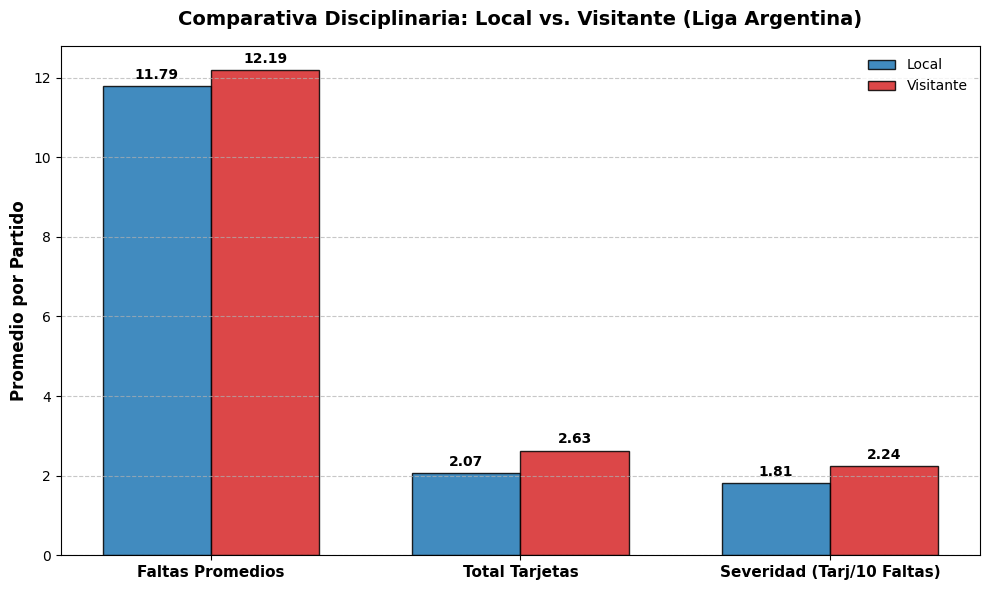

In [20]:
# 5. Generación de gráfico comparativo disciplinario y exportación para Overleaf.

# A) Configuración del lienzo y subplots
fig, ax = plt.subplots(figsize=(10, 6))

# B) Selección de métricas clave a graficar
metricas = ['Faltas Promedios', 'Total Tarjetas', 'Severidad (Tarj/10 Faltas)']
valores_local = [11.79, 2.07, 1.81]
valores_vis = [12.19, 2.63, 2.24]

x = np.arange(len(metricas))
ancho_barra = 0.35

# C) Trazado de las barras comparativas
barras1 = ax.bar(x - ancho_barra/2, valores_local, ancho_barra, label='Local', color='#1f77b4', edgecolor='black', alpha=0.85)
barras2 = ax.bar(x + ancho_barra/2, valores_vis, ancho_barra, label='Visitante', color='#d62728', edgecolor='black', alpha=0.85)

# D) Personalización de etiquetas y títulos
ax.set_ylabel('Promedio por Partido', fontsize=12, fontweight='bold')
ax.set_title('Comparativa Disciplinaria: Local vs. Visitante (Liga Argentina)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11, fontweight='bold')
ax.legend(frameon=True, facecolor='white', edgecolor='none')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# E) Inserción de valores numéricos sobre cada barra (data labels)
def agregar_etiquetas(barras):
    for barra in barras:
        alto = barra.get_height()
        ax.annotate(f'{alto:.2f}',
                    xy=(barra.get_x() + barra.get_width() / 2, alto),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

agregar_etiquetas(barras1)
agregar_etiquetas(barras2)

plt.tight_layout()

# F) Guardado de la imagen para importar en la carpeta del informe de GitHub/Overleaf
plt.savefig('grafico_disciplina_localia.png', dpi=300, bbox_inches='tight')
plt.show()



### 6. Síntesis e Interpretación de Hallazgos Disciplinarios:

A partir del análisis cuantitativo y la visualización realizada, se confirman las siguientes conclusiones respecto al sesgo disciplinario:

1. **Evidencia de Sesgo Arbitral:** Existe una disparidad sistemática entre la condición de local y visitante. Mientras que las infracciones cometidas son similares (11.79 local vs. 12.19 visitante), el visitante recibe **0.56 tarjetas adicionales por partido** (+27% de amonestaciones y el doble de expulsiones).
2. **Mayor Severidad por Infracción:** El criterio de juzgamiento no es simétrico: la visita recibe **2.24 tarjetas por cada 10 faltas**, comparado a las **1.81 del local** (un criterio un 23.7% más severo).
3. **Comportamiento según el Trámite:** En los partidos con victoria local, la brecha de amonestaciones alcanza su máximo histórico (2.82 tarjetas al visitante vs. 1.89 al local), evidenciando que el control disciplinario del visitante se intensifica cuando el local domina en el marcador.